<a href="https://colab.research.google.com/github/Amadi200/montra_hospitality/blob/main/04_BERTopic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/Amadi200/montra_hospitality.git
%cd montra_hospitality
!pip install -r requirements.txt
!python app.py

Cloning into 'montra_hospitality'...
remote: Enumerating objects: 67, done.
remote: Counting objects: 100% (67/67), done.
remote: Compressing objects: 100% (54/54), done.
remote: Total 67 (delta 11), reused 56 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (67/67), 7.29 MiB | 14.69 MiB/s, done.
Resolving deltas: 100% (11/11), done.
/content/montra_hospitality
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 13.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 18.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 22.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 20.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 19.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 22.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22/22 [bertopic]
python3: can't open file '/content/montra_hospitality/app.py': [Errno 2] No such file or directory


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving cleaned_reviews.parquet to cleaned_reviews.parquet


In [ ]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

pd.set_option("display.max_colwidth", 150)
pd.set_option("display.max_columns", 50)

In [ ]:
df = pd.read_parquet("cleaned_reviews.parquet")

In [ ]:
df.head()

,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label,bk_guest_id,bk_hotel_id,bk_room_type,bk_booking_channel,bk_check_in_date,bk_check_out_date,bk_total_amount,bk_stay_duration,gt_customer_type,gt_loyalty_status,gt_country,gt_previous_stays,ht_hotel_name,ht_location,ht_star_rating,ht_total_rooms,review_text_clean,review_text_ml,text_length,word_count
0,1,1,6699,18,"The overall price was fair for what we paid. Might consider it again, might not.",3.2,2025-06-02,neutral,6699,18,Suite,Direct Website,2025-05-25,2025-05-26,296.44,1,Leisure,None,France,4,The Aberdeen Grand,Aberdeen,4,118,"The overall price was fair for what we paid. Might consider it again, might not.",the overall price was fair for what we paid might consider it again might not,80,15
1,2,2,11380,23,"The room was nothing out of the ordinary for what we paid. The overall price exceeded our expectations — a great deal, and the quality easily matc...",4.0,2025-01-22,positive,11380,23,Deluxe,Corporate Portal,2025-01-09,2025-01-13,483.56,4,Business,Gold,Germany,4,Nottingham Park Hotel,Nottingham,4,95,"The room was nothing out of the ordinary for what we paid. The overall price exceeded our expectations a great deal, and the quality easily matche...",the room was nothing out of the ordinary for what we paid the overall price exceeded our expectations a great deal and the quality easily matched ...,158,28
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clearly needed some upkeep. Wouldn't recommend it to others.",1.9,2025-03-13,negative,4812,13,Executive,Travel Agent,2025-03-04,2025-03-06,415.59,2,Business,None,Ireland,4,The London Boutique,London,4,231,"Unfortunately, the pool was outdated it clearly needed some upkeep. Wouldn't recommend it to others.",unfortunately the pool was outdated it clearly needed some upkeep wouldn't recommend it to others,100,15
3,4,4,982,12,"We were disappointed that the neighborhood was disappointingly out of the way. Meanwhile, sadly, the room turned out to be grimy.",2.2,2026-03-18,negative,982,12,Family Room,Airbnb,2026-03-06,2026-03-09,601.18,3,Leisure,None,Nigeria,0,Manchester Metropolitan,Manchester,3,101,"We were disappointed that the neighborhood was disappointingly out of the way. Meanwhile, sadly, the room turned out to be grimy.",we were disappointed that the neighborhood was disappointingly out of the way meanwhile sadly the room turned out to be grimy,129,21
4,5,5,615,5,"The room service was standard hotel fare for what we paid. That said, the bedding was in decent shape for what we paid. On top of that, the cost o...",3.3,2025-03-03,neutral,615,5,Deluxe,Expedia,2025-02-25,2025-03-02,603.85,5,Group,None,United States,9,Glasgow Metropolitan,Glasgow,4,214,"The room service was standard hotel fare for what we paid. That said, the bedding was in decent shape for what we paid. On top of that, the cost o...",the room service was standard hotel fare for what we paid that said the bedding was in decent shape for what we paid on top of that the cost of th...,196,39


In [ ]:
print("="*60)
print("INITIAL SHAPE:", df.shape)
print("="*60)
print(df.info())
print("\nFirst 3 rows:")
display(df.head(3))

INITIAL SHAPE: (35000, 28)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 28 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   review_id           35000 non-null  int64         
 1   booking_id          35000 non-null  int64         
 2   guest_id            35000 non-null  int64         
 3   hotel_id            35000 non-null  int64         
 4   review_text         35000 non-null  object        
 5   rating_score        35000 non-null  float64       
 6   review_date         35000 non-null  datetime64[us]
 7   sentiment_label     35000 non-null  object        
 8   bk_guest_id         35000 non-null  int64         
 9   bk_hotel_id         35000 non-null  int64         
 10  bk_room_type        35000 non-null  object        
 11  bk_booking_channel  35000 non-null  object        
 12  bk_check_in_date    35000 non-null  datetime64[us]
 13  bk_check_out_date  

,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label,bk_guest_id,bk_hotel_id,bk_room_type,bk_booking_channel,bk_check_in_date,bk_check_out_date,bk_total_amount,bk_stay_duration,gt_customer_type,gt_loyalty_status,gt_country,gt_previous_stays,ht_hotel_name,ht_location,ht_star_rating,ht_total_rooms,review_text_clean,review_text_ml,text_length,word_count
0,1,1,6699,18,"The overall price was fair for what we paid. Might consider it again, might not.",3.2,2025-06-02,neutral,6699,18,Suite,Direct Website,2025-05-25,2025-05-26,296.44,1,Leisure,None,France,4,The Aberdeen Grand,Aberdeen,4,118,"The overall price was fair for what we paid. Might consider it again, might not.",the overall price was fair for what we paid might consider it again might not,80,15
1,2,2,11380,23,"The room was nothing out of the ordinary for what we paid. The overall price exceeded our expectations — a great deal, and the quality easily matc...",4.0,2025-01-22,positive,11380,23,Deluxe,Corporate Portal,2025-01-09,2025-01-13,483.56,4,Business,Gold,Germany,4,Nottingham Park Hotel,Nottingham,4,95,"The room was nothing out of the ordinary for what we paid. The overall price exceeded our expectations a great deal, and the quality easily matche...",the room was nothing out of the ordinary for what we paid the overall price exceeded our expectations a great deal and the quality easily matched ...,158,28
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clearly needed some upkeep. Wouldn't recommend it to others.",1.9,2025-03-13,negative,4812,13,Executive,Travel Agent,2025-03-04,2025-03-06,415.59,2,Business,None,Ireland,4,The London Boutique,London,4,231,"Unfortunately, the pool was outdated it clearly needed some upkeep. Wouldn't recommend it to others.",unfortunately the pool was outdated it clearly needed some upkeep wouldn't recommend it to others,100,15


STANDARDISE COLUMN NAMES



In [ ]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^\w\s]", "", regex=True)
    .str.replace(r"\s+", "_", regex=True)
)

print("\nStandardised columns:")
print(df.columns.tolist())


Standardised columns:
['review_id', 'booking_id', 'guest_id', 'hotel_id', 'review_text', 'rating_score', 'review_date', 'sentiment_label', 'bk_guest_id', 'bk_hotel_id', 'bk_room_type', 'bk_booking_channel', 'bk_check_in_date', 'bk_check_out_date', 'bk_total_amount', 'bk_stay_duration', 'gt_customer_type', 'gt_loyalty_status', 'gt_country', 'gt_previous_stays', 'ht_hotel_name', 'ht_location', 'ht_star_rating', 'ht_total_rooms', 'review_text_clean', 'review_text_ml', 'text_length', 'word_count']


MISSING VALUES ANALYSIS


MISSING VALUES REPORT


,column,missing_count,missing_pct,dtype
0,review_id,0,0.0,int64
1,booking_id,0,0.0,int64
2,guest_id,0,0.0,int64
3,hotel_id,0,0.0,int64
4,review_text,0,0.0,object
5,rating_score,0,0.0,float64
6,review_date,0,0.0,datetime64[us]
7,sentiment_label,0,0.0,object
8,bk_guest_id,0,0.0,int64
9,bk_hotel_id,0,0.0,int64


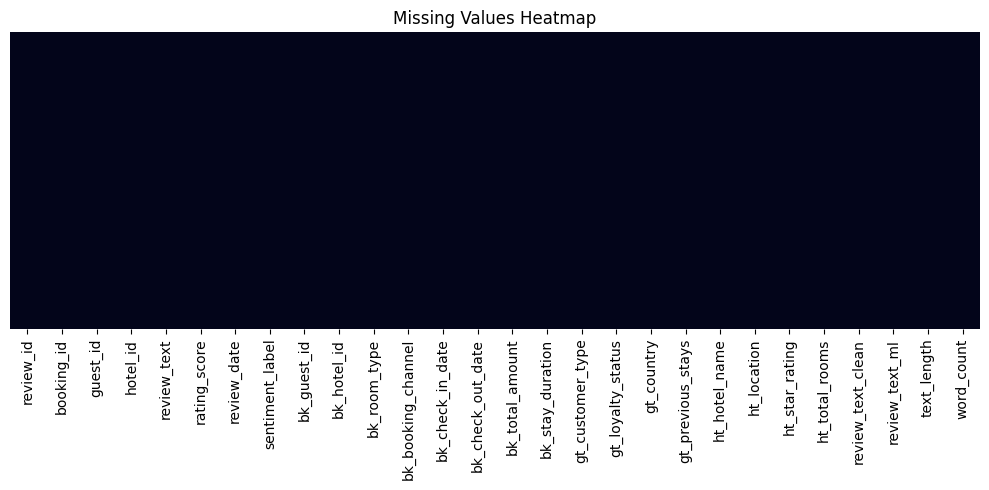

In [ ]:
def missing_report(df):
    missing = pd.DataFrame({
        "column": df.columns,
        "missing_count": df.isnull().sum().values,
        "missing_pct": (df.isnull().sum() / len(df) * 100).round(2).values,
        "dtype": df.dtypes.values
    })
    return missing.sort_values("missing_pct", ascending=False)

print("\n" + "="*60)
print("MISSING VALUES REPORT")
print("="*60)
display(missing_report(df))

# Visual
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values Heatmap")
plt.tight_layout()
plt.show()

DUPLICATES

In [ ]:
print("\n" + "="*60)
print("DUPLICATES")
print("="*60)

# Exact full-row duplicates
exact_dups = df.duplicated().sum()
print(f"Exact full-row duplicates: {exact_dups}")

# Duplicates on review text only (very important for NLP)
if "review_text" in df.columns:
    text_dups = df.duplicated(subset=["review_text"]).sum()
    print(f"Duplicate review texts: {text_dups}")

# Duplicates on key business identifiers (adjust columns)
id_cols = [c for c in ["review_id", "booking_id", "guest_id", "hotel_id"] if c in df.columns]
if id_cols:
    id_dups = df.duplicated(subset=id_cols).sum()
    print(f"Duplicates on {id_cols}: {id_dups}")


DUPLICATES
Exact full-row duplicates: 0
Duplicate review texts: 464
Duplicates on ['review_id', 'booking_id', 'guest_id', 'hotel_id']: 0


TEXT QUALITY CHECKS

In [ ]:
print("\n" + "="*60)
print("TEXT QUALITY CHECKS")
print("="*60)

text_col = "review_text"   # ← change if your column has a different name

if text_col not in df.columns:
    raise ValueError(f"Column '{text_col}' not found. Available columns: {df.columns.tolist()}")

# Basic text stats
df["_text_length"] = df[text_col].astype(str).str.len()
df["_word_count"]  = df[text_col].astype(str).str.split().str.len()

print(df[["_text_length", "_word_count"]].describe().round(1))

# Very short / empty reviews
empty_or_nan = df[text_col].isna() | (df[text_col].astype(str).str.strip() == "")
very_short   = df["_word_count"] < 3          # less than 3 words
short        = df["_word_count"] < 5

print(f"\nEmpty / NaN reviews          : {empty_or_nan.sum()}")
print(f"Reviews with < 3 words       : {very_short.sum()}")
print(f"Reviews with < 5 words       : {short.sum()}")


TEXT QUALITY CHECKS
       _text_length  _word_count
count       35000.0      35000.0
mean          171.9         29.2
std            39.8          6.6
min            67.0         13.0
25%           143.0         24.0
50%           172.0         29.0
75%           203.0         35.0
max           280.0         40.0

Empty / NaN reviews          : 0
Reviews with < 3 words       : 0
Reviews with < 5 words       : 0


DEEP CLEANING FUNCTION

In [ ]:
def clean_review_text(text):
    if pd.isna(text):
        return np.nan

    text = str(text)

    # 1. Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # 2. Remove URLs
    text = re.sub(r"http\S+|www\.\S+", " ", text)

    # 3. Remove emails
    text = re.sub(r"\S+@\S+", " ", text)

    # 4. Remove mentions / hashtags (optional)
    text = re.sub(r"@\w+|#\w+", " ", text)

    # 5. Keep letters, numbers, basic punctuation (important for sentiment)
    #    Remove excessive special characters but keep .,!?'-
    text = re.sub(r"[^a-zA-Z0-9\s\.\,\!\?\'\-\’]", " ", text)

    # 6. Fix multiple spaces / newlines / tabs
    text = re.sub(r"\s+", " ", text)

    # 7. Strip
    text = text.strip()

    # 8. Optional: lowercase (BERTopic + modern embeddings usually prefer original case,
    #    but many pipelines still lowercase. Decide based on your experiment.)
    # text = text.lower()

    return text if text else np.nan


# Apply cleaning
print("\nCleaning review text...")
df["review_text_clean"] = df[text_col].apply(clean_review_text)

# Re-calculate length after cleaning
df["_clean_word_count"] = df["review_text_clean"].astype(str).str.split().str.len()
df["_clean_word_count"] = df["_clean_word_count"].where(df["review_text_clean"].notna(), 0)


Cleaning review text...


FILTERING RULES

In [ ]:
print("\n" + "="*60)
print("APPLYING FILTERS")
print("="*60)

initial_rows = len(df)

# Rule 1: Drop rows with no usable text after cleaning
df = df[df["review_text_clean"].notna()].copy()
print(f"After removing empty cleaned text : {len(df):,} rows  (−{initial_rows - len(df)})")

# Rule 2: Drop extremely short reviews (usually noise)
MIN_WORDS = 4          # ← adjust (3–6 is common)
df = df[df["_clean_word_count"] >= MIN_WORDS].copy()
print(f"After removing < {MIN_WORDS} words       : {len(df):,} rows")

# Rule 3: Optional – remove exact duplicate cleaned texts
before = len(df)
df = df.drop_duplicates(subset=["review_text_clean"], keep="first")
print(f"After removing duplicate texts   : {len(df):,} rows  (−{before - len(df)})")


APPLYING FILTERS
After removing empty cleaned text : 35,000 rows  (−0)
After removing < 4 words       : 35,000 rows
After removing duplicate texts   : 34,536 rows  (−464)


ADDITIONAL DATA QUALITY CHECKS

In [ ]:
print("\n" + "="*60)
print("ADDITIONAL CHECKS")
print("="*60)

# Rating range (if you have a rating column)
if "rating" in df.columns or "overall_rating" in df.columns:
    rating_col = "rating" if "rating" in df.columns else "overall_rating"
    print(f"\nRating distribution ({rating_col}):")
    print(df[rating_col].value_counts(dropna=False).sort_index())

    # Flag suspicious ratings
    invalid_ratings = ~df[rating_col].between(1, 5) & df[rating_col].notna()
    print(f"Invalid ratings (not 1-5): {invalid_ratings.sum()}")

# Date parsing (if available)
date_cols = [c for c in df.columns if "date" in c or "time" in c]
for col in date_cols:
    try:
        df[col] = pd.to_datetime(df[col], errors="coerce")
        print(f"Parsed {col} → {df[col].isna().sum()} failed")
    except:
        pass


ADDITIONAL CHECKS
Parsed review_date → 0 failed
Parsed sentiment_label → 34536 failed
Parsed bk_check_in_date → 0 failed
Parsed bk_check_out_date → 0 failed


FINAL CLEAN DATASET

In [ ]:
print("\n" + "="*60)
print("FINAL CLEAN DATASET")
print("="*60)

# Keep useful columns + the cleaned text
cols_to_keep = [c for c in df.columns if not c.startswith("_")]
df_clean = df[cols_to_keep].copy()

# Make the clean text the main column
df_clean = df_clean.rename(columns={"review_text_clean": "review_text"})
# If you still need the original, keep both

print(f"Final shape: {df_clean.shape}")
print(f"\nMemory usage: {df_clean.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

# Quick look
display(df_clean[["review_text"]].head(5))


FINAL CLEAN DATASET
Final shape: (34536, 28)

Memory usage: 44.7 MB


,review_text,review_text
0,"The overall price was fair for what we paid. Might consider it again, might not.","The overall price was fair for what we paid. Might consider it again, might not."
1,"The room was nothing out of the ordinary for what we paid. The overall price exceeded our expectations — a great deal, and the quality easily matc...","The room was nothing out of the ordinary for what we paid. The overall price exceeded our expectations a great deal, and the quality easily matche..."
2,"Unfortunately, the pool was outdated — it clearly needed some upkeep. Wouldn't recommend it to others.","Unfortunately, the pool was outdated it clearly needed some upkeep. Wouldn't recommend it to others."
3,"We were disappointed that the neighborhood was disappointingly out of the way. Meanwhile, sadly, the room turned out to be grimy.","We were disappointed that the neighborhood was disappointingly out of the way. Meanwhile, sadly, the room turned out to be grimy."
4,"The room service was standard hotel fare for what we paid. That said, the bedding was in decent shape for what we paid. On top of that, the cost o...","The room service was standard hotel fare for what we paid. That said, the bedding was in decent shape for what we paid. On top of that, the cost o..."


In [ ]:
# Show duplicated column names
duplicate_cols = df_clean.columns[df_clean.columns.duplicated()].tolist()

print("Duplicate columns:", duplicate_cols)

Duplicate columns: []


In [ ]:
# Display all columns named review_text
print(df_clean.loc[:, df_clean.columns == "review_text"].head())

# Inspect the ML-ready text column
print(df_clean["review_text_ml"].head())

                                                                                                                                             review_text
0                                                                       The overall price was fair for what we paid. Might consider it again, might not.
1  The room was nothing out of the ordinary for what we paid. The overall price exceeded our expectations — a great deal, and the quality easily matc...
2                                                 Unfortunately, the pool was outdated — it clearly needed some upkeep. Wouldn't recommend it to others.
3                      We were disappointed that the neighborhood was disappointingly out of the way. Meanwhile, sadly, the room turned out to be grimy.
4  The room service was standard hotel fare for what we paid. That said, the bedding was in decent shape for what we paid. On top of that, the cost o...
0                                                                            the o

In [ ]:
assert df_clean.columns.is_unique, "Duplicate columns still exist!"
print("All column names are unique.")

All column names are unique.


SAVE CLEAN DATA

In [ ]:
from pathlib import Path

output_path = Path("data/cleaned")
output_path.mkdir(parents=True, exist_ok=True)

df_clean.to_parquet(output_path / "reviews_cleaned_for_bertopic.parquet", index=False)
# Also save a smaller sample for quick experiments
df_clean.sample(min(20000, len(df_clean)), random_state=42)\
        .to_parquet(output_path / "reviews_cleaned_sample_20k.parquet", index=False)

print(f"\nSaved to: {output_path}")
print("Files ready for BERTopic.")


Saved to: data/cleaned
Files ready for BERTopic.


Load Cleaned Data

In [ ]:
DATA_PATH = "data/cleaned/reviews_cleaned_for_bertopic.parquet"   # or your Colab path

df = pd.read_parquet(DATA_PATH)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nSample reviews:")
display(df[["review_text"]].head(3))

# Use the cleaned text column
docs = df["review_text"].astype(str).tolist()
print(f"\nNumber of documents for topic modelling: {len(docs):,}")

Shape: (34536, 27)
Columns: ['review_id', 'booking_id', 'guest_id', 'hotel_id', 'review_text', 'rating_score', 'review_date', 'sentiment_label', 'bk_guest_id', 'bk_hotel_id', 'bk_room_type', 'bk_booking_channel', 'bk_check_in_date', 'bk_check_out_date', 'bk_total_amount', 'bk_stay_duration', 'gt_customer_type', 'gt_loyalty_status', 'gt_country', 'gt_previous_stays', 'ht_hotel_name', 'ht_location', 'ht_star_rating', 'ht_total_rooms', 'review_text_ml', 'text_length', 'word_count']

Sample reviews:


,review_text
0,"The overall price was fair for what we paid. Might consider it again, might not."
1,"The room was nothing out of the ordinary for what we paid. The overall price exceeded our expectations — a great deal, and the quality easily matc..."
2,"Unfortunately, the pool was outdated — it clearly needed some upkeep. Wouldn't recommend it to others."



Number of documents for topic modelling: 34,536


Configure BERTopic

In [ ]:
# Embedding model (good balance of speed + quality)
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

# UMAP - dimensionality reduction
umap_model = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=42
)

# HDBSCAN - clustering
hdbscan_model = HDBSCAN(
    min_cluster_size=40,        # Increase to 80–150 if you have >100k reviews
    min_samples=10,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True
)

# Vectorizer - control n-grams and stop words
vectorizer_model = CountVectorizer(
    stop_words="english",
    min_df=5,                   # ignore very rare words
    max_df=0.85,
    ngram_range=(1, 2)          # unigrams + bigrams
)

# Create the model
topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    top_n_words=12,
    nr_topics="auto",               # or set a number e.g. 25
    calculate_probabilities=False,  # set True only if needed
    verbose=True
)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Fit BERTopic

In [ ]:
print("\nFitting BERTopic... (this can take several minutes)")
topics, probs = topic_model.fit_transform(docs)

print(f"\nNumber of topics found (excluding outliers): {len(set(topics)) - (1 if -1 in topics else 0)}")
print(f"Outlier documents (topic -1): {(np.array(topics) == -1).sum()}")

2026-10-27 06:54:28,580 - BERTopic - Embedding - Transforming documents to embeddings.



Fitting BERTopic... (this can take several minutes)


Batches:   0%|          | 0/1080 [00:00<?, ?it/s]

2026-10-27 06:54:47,231 - BERTopic - Embedding - Completed ✓
2026-10-27 06:54:47,232 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-27 06:55:40,509 - BERTopic - Dimensionality - Completed ✓
2026-10-27 06:55:40,511 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-27 06:55:45,760 - BERTopic - Cluster - Completed ✓
2026-10-27 06:55:45,761 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-10-27 06:55:46,666 - BERTopic - Representation - Completed ✓
2026-10-27 06:55:46,667 - BERTopic - Topic reduction - Reducing number of topics
2026-10-27 06:55:46,719 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-27 06:55:47,540 - BERTopic - Representation - Completed ✓
2026-10-27 06:55:47,545 - BERTopic - Topic reduction - Reduced number of topics from 143 to 43



Number of topics found (excluding outliers): 42
Outlier documents (topic -1): 4406


Explore Topics

In [ ]:
topic_info = topic_model.get_topic_info()
print("\nTopic Overview:")
display(topic_info.head(20))

# Look at a specific topic
print("\nTop words in Topic 0:")
print(topic_model.get_topic(0))

print("\nRepresentative documents for Topic 0:")
display(topic_model.get_representative_docs(0)[:3])


Topic Overview:


,Topic,Count,Name,Representation,Representative_Docs
0,-1,4406,-1_hotel_check_nottingham_desk,"[hotel, check, nottingham, desk, process, check process, glasgow, start, check desk, way, impressed, genuinely impressed]","[Our time in Glasgow got off to a rocky start here. That said, i'd describe the check-in process as about average — it took the usual amount of ti..."
1,0,17834,0_hotel_visit_unremarkable_ordinary,"[hotel, visit, unremarkable, ordinary, fairly, hotel fine, glasgow, way, stood way, london, start, buffet]","[This hotel was a fine, if unremarkable, choice for our time in Glasgow. On the other hand, the dining options was decent, nothing more and nothin..."
2,1,1098,1_bathroom_bathroom area_clean_overall bathroom,"[bathroom, bathroom area, clean, overall bathroom, hadn, bathroom hadn, hadn properly, properly scrubbed, scrubbed, paid bathroom, impressed bathr...","[Unfortunately, the bathroom area was visibly dirty — the bathroom hadn't been properly scrubbed. Also, the receptionist was disorganized, which r..."
3,2,1064,2_neighborhood_rate paid_overall neighborhood_quality,"[neighborhood, rate paid, overall neighborhood, quality, central, neighborhood convenient, reasonably central, manageable, convenient manageable, ...","[Overall the neighborhood was not the most convenient but manageable, about what we expected. Would neither recommend nor avoid it., Overall the n..."
4,3,803,3_breakfast_overall breakfast_breakfast write_breakfast standard,"[breakfast, overall breakfast, breakfast write, breakfast standard, breakfast fine, breakfast decent, breakfast stood, home, write home, write, ho...","[I'd describe the breakfast as standard hotel fare — there wasn't much variety but it was edible., Overall the breakfast was nothing to write home..."
5,4,775,4_house_house cafe_cafe_cafe decent,"[house, house cafe, cafe, cafe decent, overall house, cafe standard, cafe write, cafe acceptable, decent, cafe fine, impressed house, disappointed...","[The in-house cafe was acceptable for what we paid. Would neither recommend nor avoid it., The in-house cafe was nothing to write home about, noth..."
6,5,729,5_wi fi_wi_fi_fi adequate,"[wi fi, wi, fi, fi adequate, fi basic, fi special, honestly wi, fi standard, fi exceeded, fi turned, sadly wi, functional]","[The location was not the most convenient but manageable, nothing more and nothing less. Also, the Wi-Fi was fine for our needs, nothing more and ..."
7,6,667,6_business center_center_overall business_center basic,"[business center, center, overall business, center basic, center special, center adequate, center fine, center standard, functional, expected busi...","[The business center was basic but functional, nothing more and nothing less. On top of that, the lounge was fine for our needs for what we paid.,..."
8,7,568,7_desk team_team_desk_overall desk,"[desk team, team, desk, overall desk, team okay, team fine, team reasonably, team fairly, team stood, team adequate, team acceptable, professional]","[The front desk team was acceptable for what we paid. Would neither recommend nor avoid it., The pricing was about what we expected, nothing more ..."
9,8,514,8_similar_hotels_similar hotels_charge,"[similar, hotels, similar hotels, charge, line similar, line, hotels charge, matched similar, matched, charge significantly, significantly, hotels...",[I'd describe the overall price as in line with similar hotels — it matched what similar hotels charge. An okay option if nothing else is availabl...



Top words in Topic 0:
[('hotel', np.float64(0.017176175241248676)), ('visit', np.float64(0.013396248804611231)), ('unremarkable', np.float64(0.012446631469321956)), ('ordinary', np.float64(0.012230940896718787)), ('fairly', np.float64(0.012188965897953982)), ('hotel fine', np.float64(0.012031705630780935)), ('glasgow', np.float64(0.01181597118828013)), ('way', np.float64(0.011447766738190196)), ('stood way', np.float64(0.0113759162088071)), ('london', np.float64(0.01098679660320756)), ('start', np.float64(0.010633145613246079)), ('buffet', np.float64(0.010481320785766184))]

Representative documents for Topic 0:


['This hotel was a fine, if unremarkable, choice for our time in Glasgow. On the other hand, the dining options was decent, nothing more and nothing less. Plus, the fitness facilities was standard for what we paid.',
 "This hotel was a fine, if unremarkable, choice for our time in Leeds. That said, i'd describe the gym as basic but functional — we only used it briefly but it seemed fine.",
 "I'd describe the buffet as standard hotel fare — it covered the basics fine. I'd describe the gym as basic but functional — it did the job without any surprises. Plus, getting checked in was unremarkable for what we paid."]

Assign topics back to the dataframe

In [ ]:
print("DataFrame rows:", len(df))
print("Topics:", len(topics))

if probs is not None:
    print("Probabilities:", len(probs))

DataFrame rows: 34536
Topics: 34536
Probabilities: 34536


In [ ]:
# Clean / filter first
df = df.dropna(subset=["review_text"]).copy()
df = df[df["review_text"].str.strip() != ""].copy()

# Then create docs
docs = df["review_text"].astype(str).tolist()

# Then fit
topics, probs = topic_model.fit_transform(docs)

# Then assign
df["topic"] = topics

2026-10-27 06:55:58,097 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/1080 [00:00<?, ?it/s]

2026-10-27 06:56:14,710 - BERTopic - Embedding - Completed ✓
2026-10-27 06:56:14,711 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-27 06:56:49,725 - BERTopic - Dimensionality - Completed ✓
2026-10-27 06:56:49,728 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-27 06:56:51,147 - BERTopic - Cluster - Completed ✓
2026-10-27 06:56:51,148 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-10-27 06:56:52,063 - BERTopic - Representation - Completed ✓
2026-10-27 06:56:52,064 - BERTopic - Topic reduction - Reducing number of topics
2026-10-27 06:56:52,119 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-27 06:56:53,036 - BERTopic - Representation - Completed ✓
2026-10-27 06:56:53,042 - BERTopic - Topic reduction - Reduced number of topics from 143 to 43


In [ ]:
df["topic"] = topics

if probs is not None:
    df["topic_probability"] = [max(p) if isinstance(p, (list, np.ndarray)) else p for p in probs]

print("\nTopic distribution:")
print(df["topic"].value_counts().head(15))


Topic distribution:
topic
 0     17834
-1      4406
 1      1098
 2      1064
 3       803
 4       775
 5       729
 6       667
 7       568
 8       514
 9       475
 10      430
 11      401
 12      397
 13      384
Name: count, dtype: int64


Visualizations

In [ ]:
# Intertopic distance map
fig1 = topic_model.visualize_topics()
fig1.show()

# Top topics bar chart
fig2 = topic_model.visualize_barchart(top_n_topics=15, n_words=8)
fig2.show()

# Hierarchy
fig3 = topic_model.visualize_hierarchy(top_n_topics=30)
fig3.show()

# Optional: documents and topics
fig4 = topic_model.visualize_documents(docs, topics=topics, hide_annotations=True)
fig4.show()

Save everything

In [ ]:
output_dir = Path("outputs/bertopic")
output_dir.mkdir(parents=True, exist_ok=True)

# Save model
topic_model.save(
    output_dir / "bertopic_model",
    serialization="safetensors",
    save_ctfidf=True,
    save_embedding_model="sentence-transformers/all-MiniLM-L6-v2"
)

# Save results
df.to_parquet(output_dir / "reviews_with_topics.parquet", index=False)
topic_info.to_csv(output_dir / "topic_info.csv", index=False)

# Save representative documents
import pickle
with open(output_dir / "representative_docs.pkl", "wb") as f:
    pickle.dump(topic_model.get_representative_docs(), f)

print(f"\nAll results saved to: {output_dir.resolve()}")


All results saved to: /content/montra_hospitality/outputs/bertopic


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

# Create main project folder + subfolders
project_path = Path("/content/drive/MyDrive/Montra_Hospitality")
bertopic_path = project_path / "outputs" / "bertopic"
sentiment_path = project_path / "outputs" / "topic_sentiment"

bertopic_path.mkdir(parents=True, exist_ok=True)
sentiment_path.mkdir(parents=True, exist_ok=True)

print("Folders created successfully:")
print(bertopic_path)
print(sentiment_path)

Folders created successfully:
/content/drive/MyDrive/Montra_Hospitality/outputs/bertopic
/content/drive/MyDrive/Montra_Hospitality/outputs/topic_sentiment


In [ ]:
# ---------- Save everything important ----------

# 1. Save the dataframe with topics
df.to_parquet(bertopic_path / "reviews_with_topics.parquet", index=False)

# 2. Save topic info
topic_info = topic_model.get_topic_info()
topic_info.to_csv(bertopic_path / "topic_info.csv", index=False)

# 3. Save the BERTopic model itself
topic_model.save(
    bertopic_path / "bertopic_model",
    serialization="safetensors",
    save_ctfidf=True,
    save_embedding_model="sentence-transformers/all-MiniLM-L6-v2"
)

print("All BERTopic results saved to Google Drive!")
print(bertopic_path)

All BERTopic results saved to Google Drive!
/content/drive/MyDrive/Montra_Hospitality/outputs/bertopic
